# Example 5.6 — Trace potent compounds to their patents (BTK inhibitors)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:54Z
- **Contents:** 1 exchange · 8 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/5.6-patent-provenance-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 5.6-patent-provenance-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 5.6-patent-provenance-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/5.6-patent-provenance-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 5.6-patent-provenance-notebook-rerun.ipynb 5.6-patent-provenance-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Which patents report the most potent BTK inhibitors, and in which years were they published?

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:53 UTC
await replay.call(1, 'search_targets', {'query': 'BTK', 'organism': 'Homo sapiens'},
                  sha256='d7537274727692a3f4d69f8ef0f27a6277d535c9f2bfa43c0b8b82ec16697982')

**Call 1** · `search_targets` · recorded result · sha256 `d75372747276…`

_6 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1846 | Tyrosine-protein kinase BTK | Q06187 | Q06187 | Homo sapiens | Enzyme | 23124 | 13927 | BTK |
| polymer | 502 | Tyrosine-protein kinase BTK \[C481S\] | Q06187 | Q06187\[C481S\] | Homo sapiens | Enzyme Catalytic Domain | 1018 | 854 | BTK |
| polymer | 934 | Tyrosine-protein kinase BTK \[386-659\] | Q06187 | Q06187\[386-659\] | Homo sapiens | Enzyme Catalytic Domain | 937 | 789 | BTK |
| polymer | 479 | Tyrosine-protein kinase BTK \[393-659\] | Q06187 | Q06187\[393-659\] | Homo sapiens | Enzyme Catalytic Domain | 358 | 354 | BTK |
| polymer | 1098 | Tyrosine-protein kinase BTK \[328-659\] | Q06187 | Q06187\[328-659\] | Homo sapiens | Enzyme Catalytic Domain | 122 | 121 | BTK |
| polymer | 1511 | Tyrosine-protein kinase BTK \[14-552\] | Q06187 | Q06187\[14-552\] | Homo sapiens | Enzyme Catalytic Domain | 146 | 144 | Tyrosine-protein kinase BTK \[14-552\] |


In [ ]:
# Call 2 · run_sql · ran 2026-11-24 04:55:53 UTC
sql = """
    SELECT CASE WHEN regexp_matches(source_id,'^(US|WO|EP|JP|CN|KR|CA|AU)') THEN 'patent' WHEN regexp_matches(source_id,'^[0-9]+$') THEN 'article' ELSE 'other' END source_type, count(*) measurements, count(distinct monomerid) compounds, count(distinct source_id) sources, count(*) FILTER (WHERE relation='=') exact FROM activity WHERE polymerid=1846 GROUP BY 1 ORDER BY 1
    
"""
await replay.call(2, 'run_sql', {'sql': sql},
                  sha256='0a31f9d21ac39fe2eac378bf483873575c76419a21f5a1c868c0fc1820015f84')

**Call 2** · `run_sql` · recorded result · sha256 `0a31f9d21ac3…`

_3 rows_

| source_type | measurements | compounds | sources | exact |
| --- | --- | --- | --- | --- |
| article | 4005 | 2533 | 303 | 3630 |
| other | 6 | 6 | 1 | 6 |
| patent | 19113 | 11850 | 217 | 13611 |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:53 UTC
sql = """
    SELECT source_id, year, count(distinct monomerid) comps, count(distinct monomerid) FILTER (WHERE affinity_type='IC50' AND relation='=' AND value<=1) sub1nm, min(value) FILTER (WHERE affinity_type='IC50' AND relation='=') best
    FROM activity WHERE polymerid=1846 AND regexp_matches(source_id,'^(US|WO|EP|JP|CN|KR|CA|AU)')
    GROUP BY 1,2 ORDER BY sub1nm DESC, source_id LIMIT 14;
    
"""
await replay.call(3, 'run_sql', {'sql': sql},
                  sha256='730626dbeb6351d95ac22634cdd446c3bd809a487e0863614a33f058f8babe4d')

**Call 3** · `run_sql` · recorded result · sha256 `730626dbeb63…`

_14 rows_

| source_id | year | comps | sub1nm | best |
| --- | --- | --- | --- | --- |
| US10676434-B2 | 2020 | 178 | 132 | 0.046 |
| US10266491-B2 | 2019 | 168 | 122 | 0.046 |
| US11053197-B2 | 2021 | 165 | 119 | 0.046 |
| US9481682-B2 | 2016 | 220 | 105 | 0.058 |
| US9688629-B2 | 2017 | 223 | 93 | 0.04 |
| US10604504-B2 | 2020 | 222 | 92 | 0.04 |
| US11623921-B2 | 2023 | 223 | 91 | 0.04 |
| US9920031-B2 | 2018 | 218 | 89 | 0.04 |
| US10087188-B2 | 2018 | 192 | 87 | 0.13 |
| US9802915-B2 | 2017 | 215 | 87 | 0.04 |
| US9334290-B2 | 2016 | 60 | 50 | 0.18 |
| US10214546-B2 | 2019 | 174 | 41 | 0.07 |
| US20250340560-A1 | 2025 | 218 | 41 | 0.13 |
| US9447106-B2 | 2016 | 217 | 41 | 0.13 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:55:53 UTC
sql = """
    WITH p AS (SELECT DISTINCT source_id, monomerid FROM activity WHERE polymerid=1846 AND affinity_type='IC50' AND relation='=' AND value<=1 AND regexp_matches(source_id,'^(US|WO|EP)')),
    top AS (SELECT source_id FROM p GROUP BY 1 ORDER BY count(*) DESC, source_id LIMIT 10),
    c AS (SELECT DISTINCT source_id, monomerid FROM activity WHERE polymerid=1846 AND source_id IN (SELECT source_id FROM top))
    SELECT a.source_id a, b.source_id b, count(*) shared_compounds FROM c a JOIN c b ON a.monomerid=b.monomerid AND a.source_id<b.source_id GROUP BY 1,2 HAVING count(*)>=50 ORDER BY 1,2;
    
"""
await replay.call(4, 'run_sql', {'sql': sql},
                  sha256='f46a480c89805374acee510977ee4c2db63daaab2576c4f5819ab810741a41e9')

**Call 4** · `run_sql` · recorded result · sha256 `f46a480c8980…`

_13 rows_

| a | b | shared_compounds |
| --- | --- | --- |
| US10266491-B2 | US10676434-B2 | 162 |
| US10266491-B2 | US11053197-B2 | 162 |
| US10604504-B2 | US11623921-B2 | 219 |
| US10604504-B2 | US9688629-B2 | 214 |
| US10604504-B2 | US9802915-B2 | 210 |
| US10604504-B2 | US9920031-B2 | 212 |
| US10676434-B2 | US11053197-B2 | 160 |
| US11623921-B2 | US9688629-B2 | 218 |
| US11623921-B2 | US9802915-B2 | 214 |
| US11623921-B2 | US9920031-B2 | 216 |
| US9688629-B2 | US9802915-B2 | 209 |
| US9688629-B2 | US9920031-B2 | 211 |
| US9802915-B2 | US9920031-B2 | 212 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:55:53 UTC
sql = """
    SELECT a.monomerid, a.compound_name, a.source_id, a.year, a.value, a.inchi_key, a.ki_result_id, a.entryid FROM activity a WHERE polymerid=1846 AND affinity_type='IC50' AND relation='=' AND regexp_matches(source_id,'^(US|WO|EP)') ORDER BY value, monomerid LIMIT 25
    
"""
await replay.call(5, 'run_sql', {'sql': sql},
                  sha256='fce6f000b61f37cef8793e3412a57c891c2f62f8fd8b3f6311919270f89af035')

**Call 5** · `run_sql` · recorded result · sha256 `fce6f000b61f…`

```json
{
  "order_warning": "Rows 6 and 7 tie on every ORDER BY column (value, monomerid), so rows like them can swap places from run to run. End the ORDER BY with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_25 rows_

| monomerid | compound_name | source_id | year | value | inchi_key | ki_result_id | entryid |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 281761 | 4-(2-acryloyl-1,2,3,4- tetrahydroisoquinolin- 5-yl)-6-chloro-3-fluoro- 9H-carbazole-1- carboxamide | US10023534-B2 | 2018 | 0.00026 | PRKMJLHNBXYDTM-UHFFFAOYSA-N | 536982 | 610 |
| 281762 | 4-(2-acryloyl-1,2,3,4- tetrahydroisoquinolin- 5-yl)-3-fluoro-9H- carbazole-1- carboxamide | US10023534-B2 | 2018 | 0.0003 | HDEWPPNPDPMPSC-UHFFFAOYSA-N | 536983 | 610 |
| 281763 | 9-(2-acryloyl-1,2,3,4- tetrahydroisoquinolin- 5-yl)-8-fluoro-5H- pyrido\[4,3-b\]indole-6- carboxamide | US10023534-B2 | 2018 | 0.0003 | YVNOLRLSCNMLIY-UHFFFAOYSA-N | 536984 | 610 |
| 281764 | 5-(2-acryloyl-1,2,3,4- tetrahydroisoquinolin- 5-yl)-6-chloro-2,3,4,9- tetrahydro-1H- carbazole-8- carboxamide | US10023534-B2 | 2018 | 0.0006 | KSOJWLQEAAJFEY-UHFFFAOYSA-N | 536985 | 610 |
| 281758 | 4-(2-acryloyl-1,2,3,4- tetrahydroisoquinolin- 5-yl)-3-fluoro-7-(2- fluoroethyl)-9H- carbazole-1- carboxamide | US10023534-B2 | 2018 | 0.029 | AZUKRIAOZXZCBL-UHFFFAOYSA-N | 536979 | 610 |
| 662949 | US20240109877, Example 3 | US20240109877-A1 | 2024 | 0.034 | XTTYHHPEDDXLEH-HHHXNRCGSA-N | 1398289 | 11938 |
| 662949 | US20240109877, Example 3 | US20250304568-A1 | 2025 | 0.034 | XTTYHHPEDDXLEH-HHHXNRCGSA-N | 1246313 | 13296 |
| 708087 | US12172992, Example 3 | US12172992-B2 | 2024 | 0.034 | XTTYHHPEDDXLEH-HHHXNRCGSA-N | 1470410 | 12537 |
| 662958 | US20240109877, Example 12 | US20240109877-A1 | 2024 | 0.036 | VCYKHFWTVADJIM-AREMUKBSSA-N | 1398307 | 11938 |
| 662958 | US20240109877, Example 12 | US20250304568-A1 | 2025 | 0.036 | VCYKHFWTVADJIM-AREMUKBSSA-N | 1246331 | 13296 |
| 708096 | US12172992, Example 12 | US12172992-B2 | 2024 | 0.036 | VCYKHFWTVADJIM-AREMUKBSSA-N | 1470428 | 12537 |
| 165511 | US9688629, 167 | US10604504-B2 | 2020 | 0.04 | CDCZNLRXQCCGJO-UHFFFAOYSA-N | 896343 | 9073 |
| 165511 | US9688629, 167 | US9688629-B2 | 2017 | 0.04 | CDCZNLRXQCCGJO-UHFFFAOYSA-N | 470238 | 90 |
| 165511 | US9688629, 167 | US11623921-B2 | 2023 | 0.04 | CDCZNLRXQCCGJO-UHFFFAOYSA-N | 1272773 | 11202 |
| 165511 | US9688629, 167 | US9802915-B2 | 2017 | 0.04 | CDCZNLRXQCCGJO-UHFFFAOYSA-N | 699784 | 2079 |
| 165511 | US9688629, 167 | US9920031-B2 | 2018 | 0.04 | CDCZNLRXQCCGJO-UHFFFAOYSA-N | 752388 | 2711 |
| 165960 | US9688629, 204 | US10604504-B2 | 2020 | 0.04 | BGLCRSDXKMNCHF-UHFFFAOYSA-N | 896381 | 9073 |
| 165960 | US9688629, 204 | US9688629-B2 | 2017 | 0.04 | BGLCRSDXKMNCHF-UHFFFAOYSA-N | 470276 | 90 |
| 165960 | US9688629, 204 | US11623921-B2 | 2023 | 0.04 | BGLCRSDXKMNCHF-UHFFFAOYSA-N | 1272811 | 11202 |
| 165960 | US9688629, 204 | US9920031-B2 | 2018 | 0.04 | BGLCRSDXKMNCHF-UHFFFAOYSA-N | 752426 | 2711 |
| 165960 | US9688629, 204 | US9802915-B2 | 2017 | 0.04 | BGLCRSDXKMNCHF-UHFFFAOYSA-N | 699822 | 2079 |
| 662952 | US20240109877, Example 6 | US20240109877-A1 | 2024 | 0.04 | HJKHARHYGJCYLQ-MVSFAKPFSA-N | 1398295 | 11938 |
| 662952 | US20240109877, Example 6 | US20250304568-A1 | 2025 | 0.04 | HJKHARHYGJCYLQ-MVSFAKPFSA-N | 1246319 | 13296 |
| 708090 | US12172992, Example 6 | US12172992-B2 | 2024 | 0.04 | HJKHARHYGJCYLQ-MVSFAKPFSA-N | 1470416 | 12537 |
| 281750 | 5-(2-Acryloyl-1,2,3,4-tetrahydroisoquinolin-5-yl)-6-fluoro-2-(S)-(2-hydroxypropan-2-yl)-2,3,4,9-tetrahydro-1H-carbazole-8-carboxamide (Single Diastereomer) | US10023534-B2 | 2018 | 0.045 | ZCIRGAROIKDISM-INIZCTEOSA-N | 536971 | 610 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:53 UTC
sql = """
    SELECT monomerid, count(*) n, median(value) med, min(value) best, list(DISTINCT source_id ORDER BY source_id) srcs FROM activity WHERE polymerid=1846 AND affinity_type='IC50' AND relation='=' AND monomerid IN (165511,377365) GROUP BY 1
    
"""
await replay.call(6, 'run_sql', {'sql': sql},
                  sha256='2d2ffa03c206d82284e769b6cb74e7f5b51a17afb831360180675a83ec43c8a9')

**Call 6** · `run_sql` · recorded result · sha256 `2d2ffa03c206…`

```json
{
  "order_warning": "The query has no ORDER BY, so its 2 rows can come back in a different order. Add an ORDER BY that ends with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_2 rows_

| monomerid | n | med | best | srcs |
| --- | --- | --- | --- | --- |
| 377365 | 3 | 0.046 | 0.046 | US10266491-B2, US10676434-B2, US11053197-B2 |
| 165511 | 10 | 0.205 | 0.04 | US10604504-B2, US11623921-B2, US9688629-B2, US9802915-B2, US9920031-B2 |


In [ ]:
# Call 7 · get_activity · ran 2026-11-24 04:55:53 UTC
await replay.call(7, 'get_activity', {'ki_result_id': 536982},
                  sha256='ebce958eda890d58f361ca4244dbbc1970e746647de0715cc262a2392209bb91')

**Call 7** · `get_activity` · recorded result · sha256 `ebce958eda89…`

```json
{
  "measurement": {
    "ic50": " 0.00026",
    "ki_result_id": 536982,
    "reactant_set_id": 536984,
    "temp": 298.15,
    "comments": "extracted",
    "assayid": 1,
    "entryid": 610,
    "ph": 7.4
  },
  "reactants": {
    "target_label": "Tyrosine-protein kinase BTK",
    "ligand_label": "BDBM281761",
    "substrate": "to-be-curated",
    "e_prep": null,
    "i_prep": null,
    "s_prep": null,
    "monomerid": 281761,
    "compound_name": "4-(2-acryloyl-1,2,3,4- tetrahydroisoquinolin- 5-yl)-6-chloro-3-fluoro- 9H-carbazole-1- carboxamide",
    "inchi_key": "PRKMJLHNBXYDTM-UHFFFAOYSA-N",
    "polymerid": 1846,
    "complexid": null,
    "target_name": "Tyrosine-protein kinase BTK",
    "uniprot_raw": "Q06187",
    "organism": "Homo sapiens"
  },
  "assay": {
    "assay_name": "Human Recombinant Btk Enzyme Assay",
    "description": "To V-bottom 384-well plates were added test compounds, human recombinant Btk (1 nM, Invitrogen Corporation), fluoresceinated peptide (1.5 &#956;M), ATP (20 &#956;M), and assay buffer (20 mM HEPES pH 7.4, 10 mM MgCl2, 0.015% Brij 35 surfactant and 4 mM DTT in 1.6% DMSO), with a final volume of 30 &#956;L. After incubating at room temperature for 60 min, the reaction was terminated by adding 45 &#956;L of 35 mM EDTA to each sample. The reaction mixture was analyzed on the Caliper LABCHIP 3000 (Caliper, Hopkinton, Mass.) by electrophoretic separation of the fluorescent substrate and phosphorylated product. Inhibition data were calculated by comparison to no enzyme control reactions for 100% inhibition and no inhibitor controls for 0% inhibition. Dose response curves were generated to determine the concentration required for inhibiting 50% of kinase activity (IC50). Compounds were dissolved at 10 mM in DMSO and evaluated at eleven concentrations."
  },
  "entry": {
    "entryid": 610,
    "entrytitle": "Carbazole and tetrahydrocarbazole compounds useful as inhibitors of BTK",
    "meas_tech": "Enzyme Inhibition",
    "entrydate": "2018-12-31T00:00:00",
    "ezid": "10.7270/Q2WW7KQR"
  }
}
```

**citations**: 1 row

| articleid | art_purp | title | journal | year | volume | firstpage | source_id | doi | authors |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 7043 | header5body5-20180717 | Carbazole and tetrahydrocarbazole compounds useful as inhibitors of BTK | US Patent | 2018 | 2018 |  | US10023534-B2 |  | SH Watterson, AJ Tebben, S Ahmad |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:55:53 UTC
sql = """
    SELECT year, count(distinct source_id) patents, count(distinct monomerid) compounds, count(distinct monomerid) FILTER (WHERE affinity_type='IC50' AND relation='=' AND value<=1) sub1nm FROM activity WHERE polymerid=1846 AND regexp_matches(source_id,'^(US|WO|EP|JP|CN|KR|CA|AU)') GROUP BY 1 ORDER BY 1
    
"""
await replay.call(8, 'run_sql', {'sql': sql},
                  sha256='aff550a1acde8ef4b1323a338624b8eb6a97d5f77d75151e6242665f3ce034a9')

**Call 8** · `run_sql` · recorded result · sha256 `aff550a1acde…`

_14 rows_

| year | patents | compounds | sub1nm |
| --- | --- | --- | --- |
| 2013 | 5 | 88 | 9 |
| 2014 | 3 | 100 | 24 |
| 2015 | 9 | 249 | 36 |
| 2016 | 17 | 903 | 240 |
| 2017 | 32 | 3101 | 270 |
| 2018 | 17 | 1202 | 347 |
| 2019 | 26 | 1778 | 264 |
| 2020 | 29 | 3209 | 348 |
| 2021 | 25 | 2535 | 205 |
| 2022 | 10 | 1090 | 14 |
| 2023 | 11 | 758 | 105 |
| 2024 | 15 | 737 | 59 |
| 2025 | 12 | 1150 | 63 |
| 2026 | 6 | 121 | 27 |


**Figure 1: The most potent BTK inhibitors in BindingDB patents.** _(as recorded)_

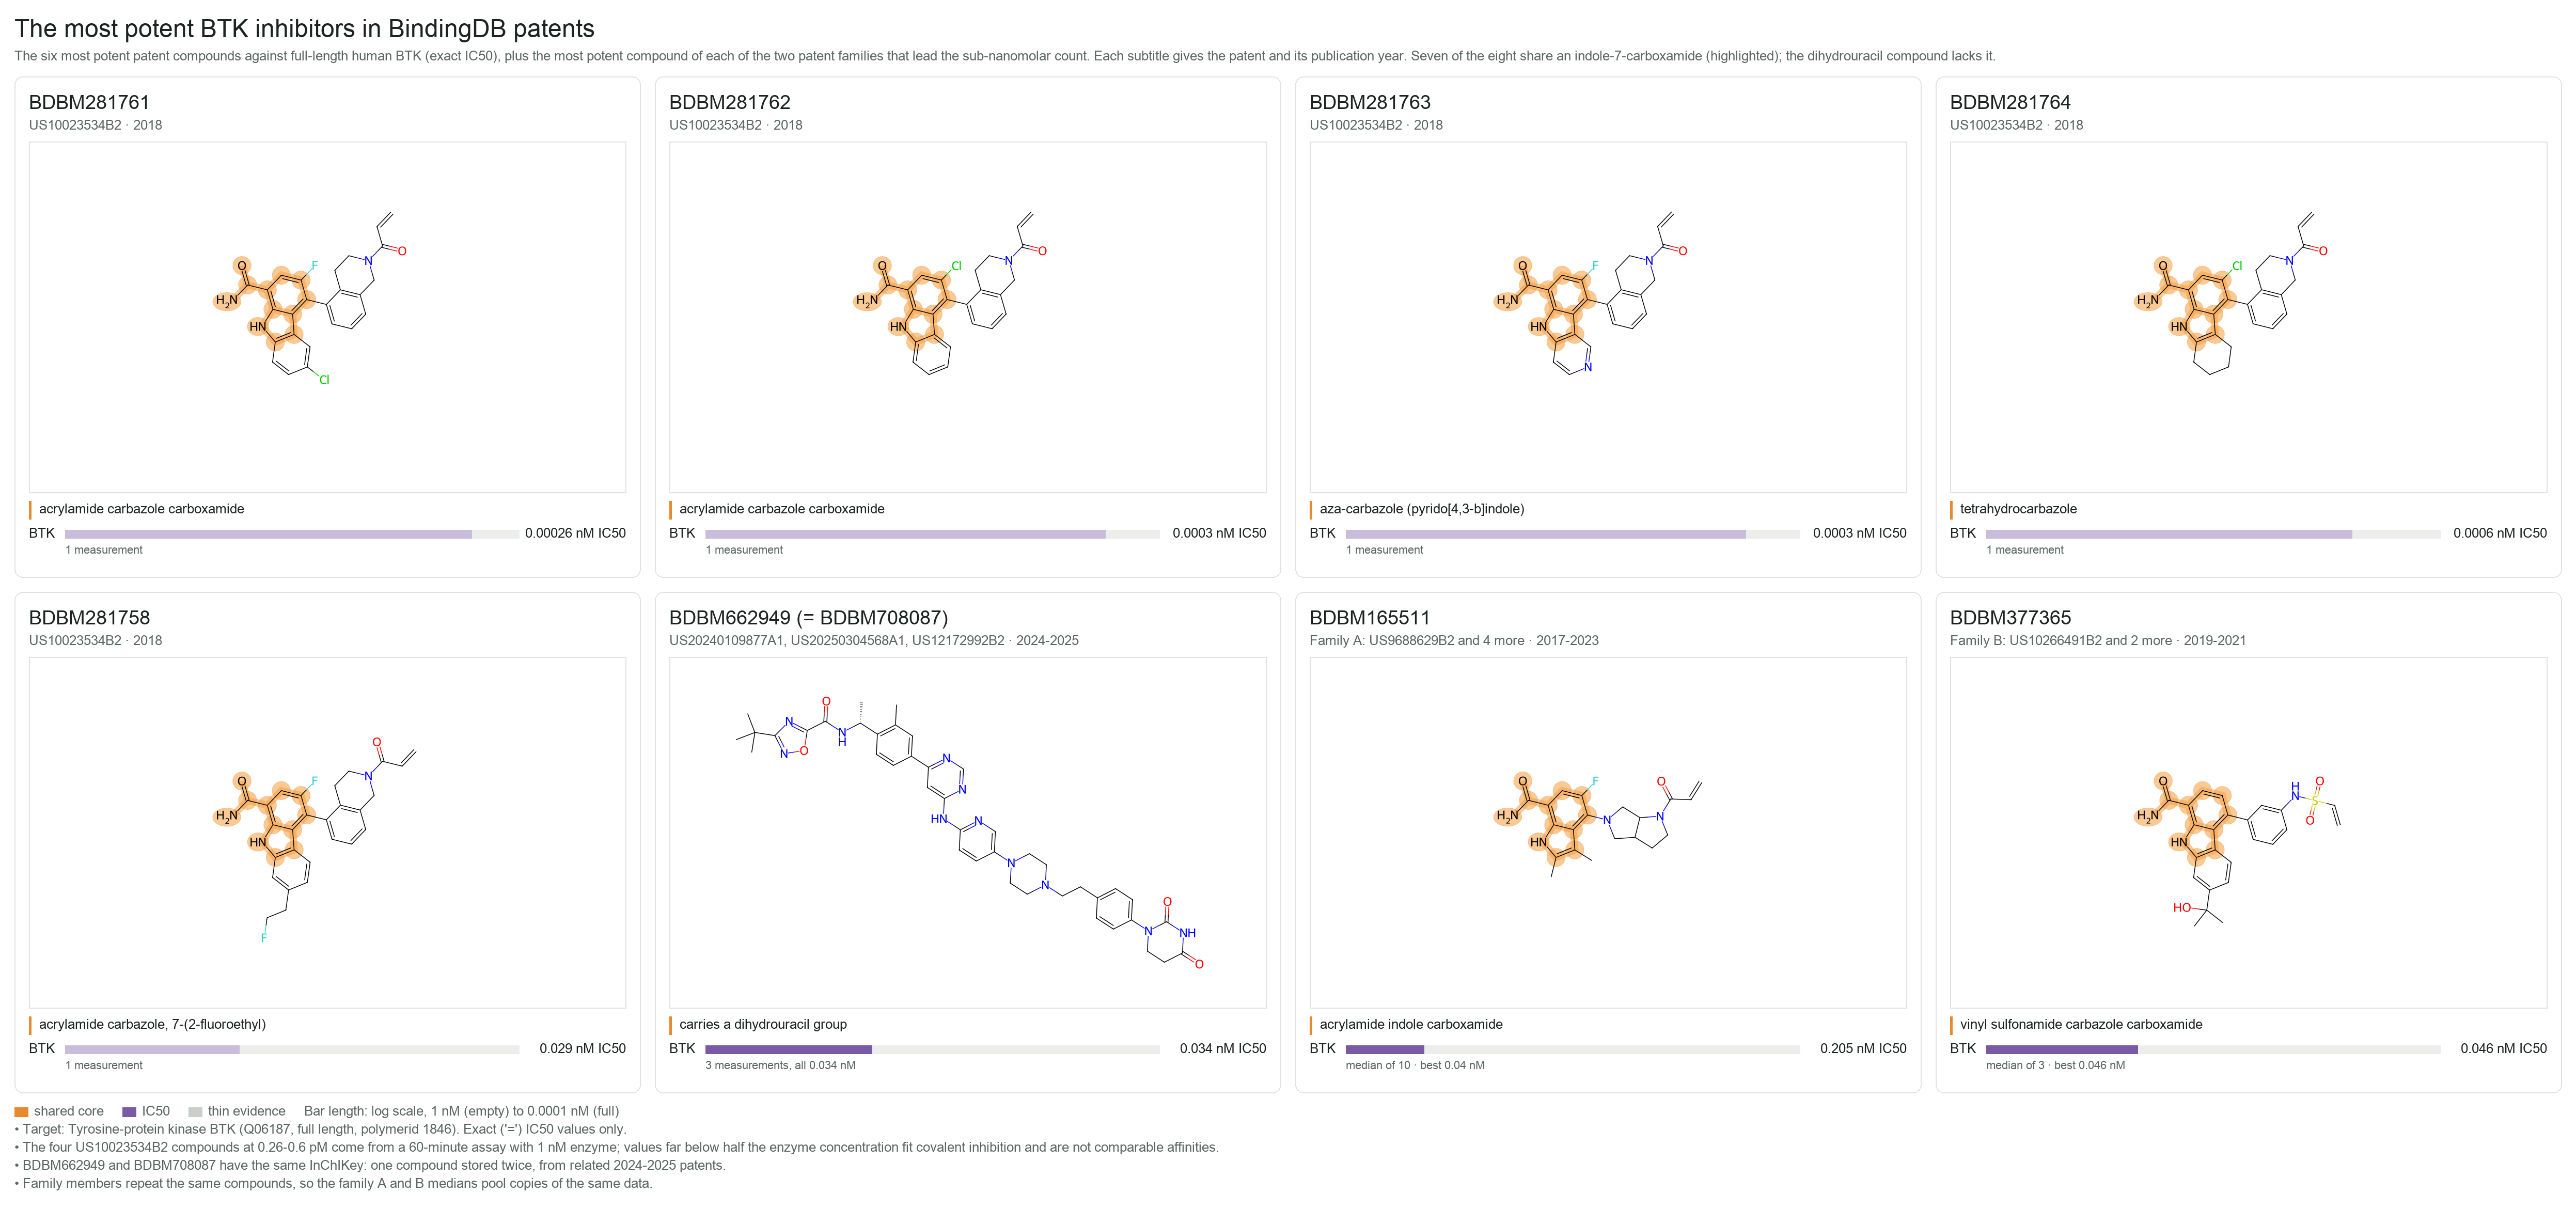

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'The most potent BTK inhibitors in BindingDB patents',
    'compounds': [
        {
            'smiles': 'C=CC(=O)N1CCc2c(cccc2-c2c(F)cc(C(N)=O)c3[nH]c4ccc(Cl)cc4c23)C1',
            'title': 'BDBM281761',
            'subtitle': 'US10023534B2 · 2018',
            'caption': 'acrylamide carbazole carboxamide',
            'bars': [
                {
                    'label': 'BTK',
                    'value_nm': 0.00026,
                    'type': 'IC50',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)N1CCc2c(cccc2-c2c(Cl)cc(C(N)=O)c3[nH]c4ccccc4c23)C1',
            'title': 'BDBM281762',
            'subtitle': 'US10023534B2 · 2018',
            'caption': 'acrylamide carbazole carboxamide',
            'bars': [
                {
                    'label': 'BTK',
                    'value_nm': 0.0003,
                    'type': 'IC50',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)N1CCc2c(cccc2-c2c(F)cc(C(N)=O)c3[nH]c4ccncc4c23)C1',
            'title': 'BDBM281763',
            'subtitle': 'US10023534B2 · 2018',
            'caption': 'aza-carbazole (pyrido[4,3-b]indole)',
            'bars': [
                {
                    'label': 'BTK',
                    'value_nm': 0.0003,
                    'type': 'IC50',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)N1CCc2c(cccc2-c2c(Cl)cc(C(N)=O)c3[nH]c4c(c23)CCCC4)C1',
            'title': 'BDBM281764',
            'subtitle': 'US10023534B2 · 2018',
            'caption': 'tetrahydrocarbazole',
            'bars': [
                {
                    'label': 'BTK',
                    'value_nm': 0.0006,
                    'type': 'IC50',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)N1CCc2c(cccc2-c2c(F)cc(C(N)=O)c3[nH]c4cc(CCF)ccc4c23)C1',
            'title': 'BDBM281758',
            'subtitle': 'US10023534B2 · 2018',
            'caption': 'acrylamide carbazole, 7-(2-fluoroethyl)',
            'bars': [
                {
                    'label': 'BTK',
                    'value_nm': 0.029,
                    'type': 'IC50',
                    'note': '1 measurement',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc6cc(c5cc(Nc4ccc(N3CCN(CCc2ccc(N1CCC(=O)NC1=O)cc2)CC3)cn4)ncn5)ccc6[C@@H](C)NC(=O)c7nc(C(C)(C)C)no7',
            'title': 'BDBM662949 (= BDBM708087)',
            'subtitle': 'US20240109877A1, US20250304568A1, US12172992B2 · 2024-2025',
            'caption': 'carries a dihydrouracil group',
            'bars': [
                {
                    'label': 'BTK',
                    'value_nm': 0.034,
                    'type': 'IC50',
                    'note': '3 measurements, all 0.034 nM',
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)N1CCC2CN(c3c(F)cc(C(N)=O)c4[nH]c(C)c(C)c34)CC21',
            'title': 'BDBM165511',
            'subtitle': 'Family A: US9688629B2 and 4 more · 2017-2023',
            'caption': 'acrylamide indole carboxamide',
            'bars': [
                {'label': 'BTK', 'value_nm': 0.205, 'type': 'IC50', 'note': 'median of 10 · best 0.04 nM'},
            ],
        },
        {
            'smiles': 'C=CS(=O)(=O)Nc1cccc(-c2ccc(C(N)=O)c3[nH]c4cc(C(C)(C)O)ccc4c23)c1',
            'title': 'BDBM377365',
            'subtitle': 'Family B: US10266491B2 and 2 more · 2019-2021',
            'caption': 'vinyl sulfonamide carbazole carboxamide',
            'bars': [
                {'label': 'BTK', 'value_nm': 0.046, 'type': 'IC50', 'note': 'median of 3 · best 0.046 nM'},
            ],
        },
    ],
    'align_to': 'NC(=O)c1cccc2cc[nH]c12',
    'columns': 4,
    'description': 'The six most potent patent compounds against full-length human BTK (exact IC50), plus the most potent compound of each of the two patent families that lead the sub-nanomolar count. Each subtitle gives the patent and its publication year. Seven of the eight share an indole-7-carboxamide (highlighted); the dihydrouracil compound lacks it.',
    'notes': [
        "Target: Tyrosine-protein kinase BTK (Q06187, full length, polymerid 1846). Exact ('=') IC50 values only.",
        'The four US10023534B2 compounds at 0.26-0.6 pM come from a 60-minute assay with 1 nM enzyme; values far below half the enzyme concentration fit covalent inhibition and are not comparable affinities.',
        'BDBM662949 and BDBM708087 have the same InChIKey: one compound stored twice, from related 2024-2025 patents.',
        'Family members repeat the same compounds, so the family A and B medians pool copies of the same data.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Patents are where most BTK data in BindingDB comes from. For human BTK (Bruton's tyrosine kinase, UniProt Q06187, the full-length target with 23,124 measurements), 19,113 measurements on 11,850 compounds come from 217 patents. Only 4,005 measurements come from 303 journal articles (plus 6 from one PubChem assay). The patent data are almost all IC50 values from enzyme assays.

There are two ways to read "most potent", and they give different answers.

**1. Patents with the most sub-nanomolar compounds** (exact IC50 at or below 1 nM):

| Patent | Published | Compounds | Compounds at or below 1 nM | Best IC50 (nM) | Family |
|---|---|---|---|---|---|
| US10676434B2 | 2020 | 178 | 132 | 0.046 | B |
| US10266491B2 | 2019 | 168 | 122 | 0.046 | B |
| US11053197B2 | 2021 | 165 | 119 | 0.046 | B |
| US9481682B2 | 2016 | 220 | 105 | 0.058 | |
| US9688629B2 | 2017 | 223 | 93 | 0.04 | A |
| US10604504B2 | 2020 | 222 | 92 | 0.04 | A |
| US11623921B2 | 2023 | 223 | 91 | 0.04 | A |
| US9920031B2 | 2018 | 218 | 89 | 0.04 | A |
| US10087188B2 | 2018 | 192 | 87 | 0.13 | |
| US9802915B2 | 2017 | 215 | 87 | 0.04 | A |

This top-10 list is really two patent families plus two single patents. Family A has five patents (2017-2023) that share 209-219 compounds with each other. Family B has three patents (2019-2021) that share 160-162 compounds. Each patent repeats largely the same compounds with the same values, so counting family members separately counts the same molecules several times. The most potent compound of each family is in the last two cards of the grid below: BDBM165511, an acrylamide indole carboxamide (family A, best 0.04 nM, median 0.205 nM over its 10 copies), and BDBM377365, a carbazole carboxamide with a vinyl sulfonamide (family B, 0.046 nM, 3 copies).

**2. The single most potent compounds.** The figure below shows the six most potent patent compounds, each with its patent, publication year and BTK IC50. The grid is aligned on an indole-7-carboxamide (12 atoms, highlighted), which seven of the eight compounds share; the dihydrouracil compound lacks it and is drawn unaligned.

The top four, and the fifth at 0.029 nM (BDBM281758), are acrylamide carbazoles from a single 2018 patent, US10023534B2, "Carbazole and tetrahydrocarbazole compounds useful as inhibitors of BTK": BDBM281761 (0.26 pM), BDBM281762 and BDBM281763 (0.3 pM each, the second an aza-carbazole) and BDBM281764 (0.6 pM, a tetrahydrocarbazole). Each has one measurement. (Note: BindingDB's name for BDBM281762 says 3-fluoro, but its stored structure carries chlorine at that position; I drew the stored structure.) The acrylamide is a reactive group that bonds covalently to BTK's Cys481, the same mechanism ibrutinib uses. The sixth compound (0.034 nM) is a newer chemotype from 2024-2025 patents (US20240109877A1, US20250304568A1, US12172992B2) that carries a dihydrouracil group, as used in cereblon-recruiting degraders. BindingDB stores it twice, as BDBM662949 and BDBM708087, with the same InChIKey.

**Tracing one value to its source.** Opening the 0.26 pM record (get_activity, measurement 536982) gives the full provenance: patent US10023534B2 by Watterson, Tebben, Ahmad et al., the assay "Human Recombinant Btk Enzyme Assay" (a Caliper mobility-shift assay, pH 7.4, 298 K, 60-minute incubation), and the curation date (BindingDB entry dated 2018-12-31). The assay description also says the enzyme concentration was 1 nM. For a reversible inhibitor, a measured IC50 cannot fall below about half the enzyme concentration, here 0.5 nM. A 0.26 pM value is roughly 2,000-fold below that, which fits a covalent inhibitor. For covalent compounds the IC50 depends on incubation time and says more about the rate of inactivation than about affinity. Treat such values as "very potent", not as a precise number to compare with other assays.

**When were the BTK patents published?** By publication year in BindingDB:

| Year | Patents | Compounds | Compounds at or below 1 nM |
|---|---|---|---|
| 2013 | 5 | 88 | 9 |
| 2015 | 9 | 249 | 36 |
| 2016 | 17 | 903 | 240 |
| 2017 | 32 | 3,101 | 270 |
| 2018 | 17 | 1,202 | 347 |
| 2019 | 26 | 1,778 | 264 |
| 2020 | 29 | 3,209 | 348 |
| 2021 | 25 | 2,535 | 205 |
| 2022 | 10 | 1,090 | 14 |
| 2023 | 11 | 758 | 105 |
| 2024 | 15 | 737 | 59 |
| 2025 | 12 | 1,150 | 63 |

(2014: 3 patents, 100 compounds, 24 at or below 1 nM; 2026 so far: 6 patents, 121 compounds, 27 at or below 1 nM.) Patent activity peaked in 2017-2021, after ibrutinib's 2013 approval.

**The lesson:** a patent's year in BindingDB is its publication or grant year, not its invention date. US patent applications are published about 18 months after filing, and grants can come years later, often after the priority date that establishes the invention. Patents in one family (A and B above) are usually continuations of one original filing, so their 2017-2023 spread is mostly legal process rather than new chemistry. To date an idea, use the earliest member of the family, and treat even that as an upper bound. Patent IC50s also need care: some patents report values in bins ("< 10 nM", 'A/B/C' categories), and BindingDB marks those with a non-"=" relation. Only 71% of BTK patent measurements are exact, compared with 91% for journal articles.

**How this was answered**

- search_targets with the query "BTK" and organism Homo sapiens: the full-length enzyme (polymerid 1846) plus five construct or mutant targets (C481S, kinase-domain fragments). I used the full-length target.
- run_sql on the activity table: split BTK measurements by source type (source_id starting with US/WO/EP = patent, a numeric id = PubMed article), and counted compounds per source.
- run_sql: ranked patents by the number of compounds with an exact IC50 at or below 1 nM, then found patent families by counting shared compounds between pairs of patents.
- run_sql: listed the most potent individual compounds with their patents and years, and the median and best value of the most potent compound of each family.
- get_activity with measurement 536982: the full record behind the most potent value, including the assay protocol, enzyme concentration and citation.
- run_sql: tallied patents, compounds and sub-nanomolar compounds per publication year.
- draw_structure_grid: the eight compounds with their patents as subtitles and a BTK IC50 bar each, aligned on the shared indole-7-carboxamide; single measurements are drawn faint.

**Try next**

- "Which BTK inhibitors were published in journal articles before they appeared in a patent?" (compare year across source types)
- "How potent are the patent compounds against the ibrutinib-resistant BTK C481S mutant?" (Example 3.3)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 8 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 5.6 — Trace potent compounds to their patents (BTK inhibitors), 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```